<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-2-MLP-Backpropagation/perceptron_xor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 1: Errors = 2
Epoch 2: Errors = 3
Epoch 3: Errors = 3
Epoch 4: Errors = 0
Epoch 5: Errors = 0
Epoch 6: Errors = 0
Epoch 7: Errors = 0
Epoch 8: Errors = 0
Epoch 9: Errors = 0
Epoch 10: Errors = 0
Epoch 11: Errors = 0
Epoch 12: Errors = 0
Epoch 13: Errors = 0
Epoch 14: Errors = 0
Epoch 15: Errors = 0
Epoch 16: Errors = 0
Epoch 17: Errors = 0
Epoch 18: Errors = 0
Epoch 19: Errors = 0
Epoch 20: Errors = 0

AND Gate Predictions:
[0 0] : -1
[0 1] : -1
[1 0] : -1
[1 1] : 1
Epoch 1: Errors = 3
Epoch 2: Errors = 3
Epoch 3: Errors = 4
Epoch 4: Errors = 4
Epoch 5: Errors = 4
Epoch 6: Errors = 4
Epoch 7: Errors = 4
Epoch 8: Errors = 4
Epoch 9: Errors = 4
Epoch 10: Errors = 4
Epoch 11: Errors = 4
Epoch 12: Errors = 4
Epoch 13: Errors = 4
Epoch 14: Errors = 4
Epoch 15: Errors = 4
Epoch 16: Errors = 4
Epoch 17: Errors = 4
Epoch 18: Errors = 4
Epoch 19: Errors = 4
Epoch 20: Errors = 4

XOR Gate Predictions:
Input: [0 0] Expected: -1 Predicted: 1
Input: [0 1] Expected: 1 Predicted: 1
Input: [1 0]

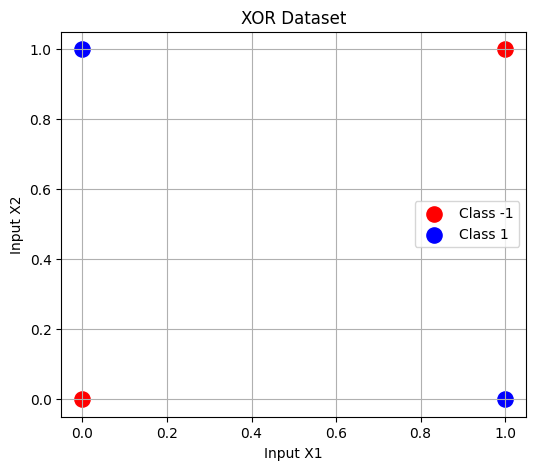

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Single Layer Perceptron

class Perceptron:

    def __init__(self, learning_rate=0.1, epochs=20):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0

    # Step activation function
    def predict(self, x):
        z = np.dot(x, self.weights) + self.bias
        return 1 if z >= 0 else -1

    # Training using Perceptron Learning Rule
    def fit(self, X, y):

        self.weights = np.zeros(X.shape[1])
        self.bias = 0

        for epoch in range(self.epochs):

            errors = 0

            for xi, target in zip(X, y):

                prediction = self.predict(xi)

                if prediction != target:

                    self.weights += self.lr * target * xi
                    self.bias += self.lr * target
                    errors += 1

            print(f"Epoch {epoch+1}: Errors = {errors}")

        return self


# Dataset: AND
X_and = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_and = np.array([-1, -1, -1, 1])

# Train AND perceptron
and_model = Perceptron()
and_model.fit(X_and, y_and)

print("\nAND Gate Predictions:")

for x in X_and:
    print(x, ":", and_model.predict(x))


# Dataset: XOR
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([-1, 1, 1, -1])

# Train XOR perceptron
xor_model = Perceptron()
xor_model.fit(X_xor, y_xor)

print("\nXOR Gate Predictions:")

correct = 0

for x, target in zip(X_xor, y_xor):

    prediction = xor_model.predict(x)

    print("Input:", x,
          "Expected:", target,
          "Predicted:", prediction)

    if prediction == target:
        correct += 1

accuracy = correct / len(y_xor) * 100

print("\nXOR Accuracy:", accuracy, "%")


# Visualize XOR dataset
plt.figure(figsize=(6, 5))

for i, point in enumerate(X_xor):

    if y_xor[i] == 1:
        plt.scatter(point[0], point[1],
                    color="blue", s=120, label="Class 1" if i == 1 else "")

    else:
        plt.scatter(point[0], point[1],
                    color="red", s=120, label="Class -1" if i == 0 else "")

plt.title("XOR Dataset")
plt.xlabel("Input X1")
plt.ylabel("Input X2")
plt.legend()
plt.grid(True)
plt.show()